# 02 — Modelagem e Avaliação

Continua do notebook 01. Toda a lógica vive em `src/phishing/`; este notebook
só chama as funções e interpreta os resultados — o que está aqui é exatamente
o que o `python -m phishing.train` executa.

**Regra do projeto:** o conjunto de teste fica trancado até a seção 4.
Toda escolha (modelo, features, limiar) é feita só com o treino.

## O que este notebook responde

1. Qual modelo, e a complexidade extra compensa?
2. Quanto cada fonte de informação (URL vs HTML) contribui?
3. Onde cortar o score para minimizar o custo de negócio?
4. Quanto o detector final acerta em dados nunca vistos?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from phishing import config, data, evaluate, train

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.axisbelow": True})
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"

df_limpo, audit = data.clean(data.load_raw())
X_tr, X_te, y_tr, y_te = data.split(df_limpo)
print(f"Treino: {len(X_tr)} | Teste: {len(X_te)} (trancado)")

Treino: 7664 | Teste: 1917 (trancado)


## 1. Comparação de modelos

Cinco candidatos, do mais simples ao mais flexível, avaliados por **validação
cruzada estratificada em 5 folds** no treino. Cada número é uma média de 5
avaliações em dados que o modelo não viu, e o desvio mostra o quanto ela
oscila — diferenças menores que o desvio são ruído.

O `dummy` (sempre prevê a classe majoritária) não é um candidato de verdade: é
o **piso**. Se algum modelo ficasse perto dele, o problema estaria no pipeline,
não no modelo.

In [2]:
ranking = train.compare_models(X_tr, y_tr)
colunas = ["model", "roc_auc_mean", "roc_auc_std", "average_precision_mean",
           "recall_mean", "precision_mean", "fit_time_s"]
ranking[colunas].round(4)

  dummy                    ROC-AUC=0.5000 (±0.0000)  [1.03s]


  logistic_regression      ROC-AUC=0.9824 (±0.0028)  [0.74s]


  decision_tree            ROC-AUC=0.9753 (±0.0026)  [0.87s]


  random_forest            ROC-AUC=0.9979 (±0.0006)  [1.63s]


  hist_gradient_boosting   ROC-AUC=0.9981 (±0.0006)  [0.54s]


,model,roc_auc_mean,roc_auc_std,average_precision_mean,recall_mean,precision_mean,fit_time_s
0,hist_gradient_boosting,0.9981,0.0006,0.9981,0.9836,0.9818,0.54
1,random_forest,0.9979,0.0006,0.9979,0.9801,0.9796,1.63
2,logistic_regression,0.9824,0.0028,0.9795,0.9463,0.9303,0.74
3,decision_tree,0.9753,0.0026,0.9628,0.9553,0.9608,0.87
4,dummy,0.5000,0.0000,0.4786,0.0000,0.0000,1.03


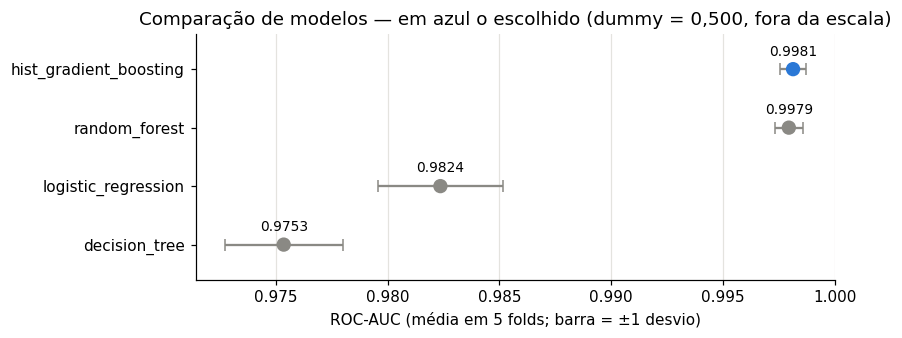

In [3]:
r = ranking[ranking["model"] != "dummy"].sort_values("roc_auc_mean")
cores = [AZUL if m == config.FINAL_MODEL else CINZA for m in r["model"]]

fig, ax = plt.subplots(figsize=(7.5, 2.9))
ax.errorbar(r["roc_auc_mean"], r["model"], xerr=r["roc_auc_std"], fmt="none",
            ecolor=CINZA, elinewidth=1.5, capsize=4)
ax.scatter(r["roc_auc_mean"], r["model"], c=cores, s=70, zorder=3)
for x, m in zip(r["roc_auc_mean"], r["model"]):
    ax.annotate(f"{x:.4f}", (x, m), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9)
ax.set(xlabel="ROC-AUC (média em 5 folds; barra = ±1 desvio)",
       title=f"Comparação de modelos — em azul o escolhido (dummy = 0,500, fora da escala)")
ax.grid(axis="y", visible=False)
ax.margins(y=0.2)
plt.show()

**Leitura:**

- **O dummy fica em 0,500**, como esperado: o pipeline não vaza o alvo.
- **A regressão logística já chega a 0,982.** Um modelo linear separa bem as
  classes, ou seja, o sinal nas features é forte, não um artefato de modelo
  complexo.
- **Uma árvore sozinha (0,975) fica abaixo da logística.** Com profundidade 6
  ela é interpretável, mas perde para o modelo linear.
- **Random forest e gradient boosting empatam** (0,9979 vs 0,9981, desvio de
  0,0006 nos dois). A diferença está dentro do ruído, então o critério de
  desempate é custo operacional: o `hist_gradient_boosting` treina ~3× mais
  rápido e o modelo salvo tem 0,4 MB contra 25 MB do random forest (~60× menor). É o `config.FINAL_MODEL`.

## 2. Ablação: URL vs HTML

No notebook 01, as features de HTML tinham correlação média maior com o alvo,
mas **associação não é desempenho**. Aqui o teste de verdade: o mesmo modelo,
os mesmos folds, treinado com cada conjunto de features.

A pergunta tem consequência prática: features de URL saem da string, **antes**
de o usuário abrir a página e sem custo de rede. As de HTML exigem baixar o
site.

In [4]:
abl = train.ablation(X_tr, y_tr)
abl[["feature_set", "n_features", "roc_auc_mean", "roc_auc_std",
     "average_precision_mean", "recall_mean", "precision_mean"]].round(4)

,feature_set,n_features,roc_auc_mean,roc_auc_std,average_precision_mean,recall_mean,precision_mean
0,url_only,27,0.9668,0.0018,0.9615,0.9111,0.8899
1,html_only,20,0.9940,0.0007,0.9933,0.9774,0.9708
2,full,47,0.9981,0.0006,0.9981,0.9836,0.9818


**Leitura:**

- **Só URL: ROC-AUC 0,967 e recall 0,91** (no limiar 0,5). É útil, mas cerca
  de 1 em cada 11 phishings passaria. Sozinha, a URL não basta para um
  bloqueio com FN valendo 10× FP.
- **Só HTML: 0,994**, já perto do conjunto completo. O conteúdo da página é a
  fonte mais informativa.
- **As duas juntas: 0,998.** O ganho sobre o HTML sozinho é pequeno em AUC,
  mas é consistente (bem acima do desvio) e reduz os erros de 2,3% para 1,6%
  dos phishings no limiar 0,5: os sinais são **complementares**, não
  redundantes.

Isso abre um desenho de sistema em dois estágios, a hipótese do notebook 01:
**a URL faz a triagem barata e o HTML só é baixado na zona cinzenta.** Testar
isso é a extensão natural do projeto.

## 3. Limiar de decisão pelo custo

O modelo devolve uma **probabilidade**; o limiar é o que a transforma em
decisão. O padrão 0,5 só é ótimo se os dois erros custarem igual — e aqui um
phishing que passa custa 10× um site legítimo bloqueado.

A pergunta delicada é **em quais scores** escolher o limiar. Não pode ser no
teste (seria ajustar à prova), e também não nos scores do modelo no próprio
treino: ele já viu essas linhas e "decora" as respostas. A comparação abaixo
mostra a diferença.

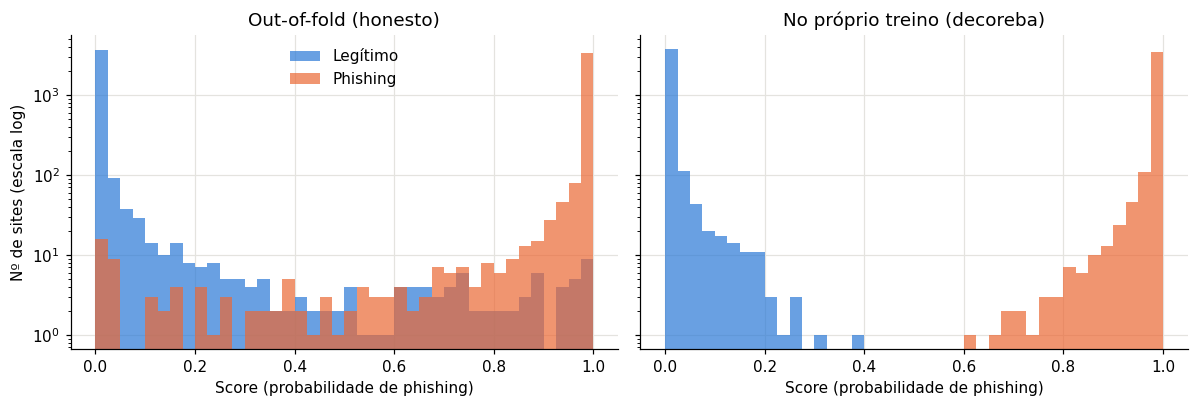

In [5]:
# Out-of-fold: cada linha recebe score de um modelo que não a viu
scores_oof = train.oof_scores(X_tr, y_tr)

# "Decoreba": treina no treino inteiro e dá score no próprio treino
from phishing import models
modelo_treino = models.get_candidates()[config.FINAL_MODEL].fit(X_tr, y_tr)
scores_treino = modelo_treino.predict_proba(X_tr)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, (titulo, s) in zip(axes, [("Out-of-fold (honesto)", scores_oof),
                                  ("No próprio treino (decoreba)", scores_treino)]):
    ax.hist(s[y_tr == 0], bins=bins, alpha=.7, color=AZUL, label="Legítimo")
    ax.hist(s[y_tr == 1], bins=bins, alpha=.7, color=LARANJA, label="Phishing")
    ax.set(title=titulo, xlabel="Score (probabilidade de phishing)", yscale="log")
axes[0].set_ylabel("Nº de sites (escala log)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

No próprio treino quase tudo fica colado em 0 ou 1: escolher o limiar ali
seria escolher num mundo onde o modelo quase não erra. Os scores out-of-fold
mostram a zona cinzenta real, onde os erros acontecem — são o substituto
honesto do teste.

,limiar,fp,fn,custo
"limiar 0,5",0.500,67,60,667.0
limiar ótimo,0.105,156,25,406.0


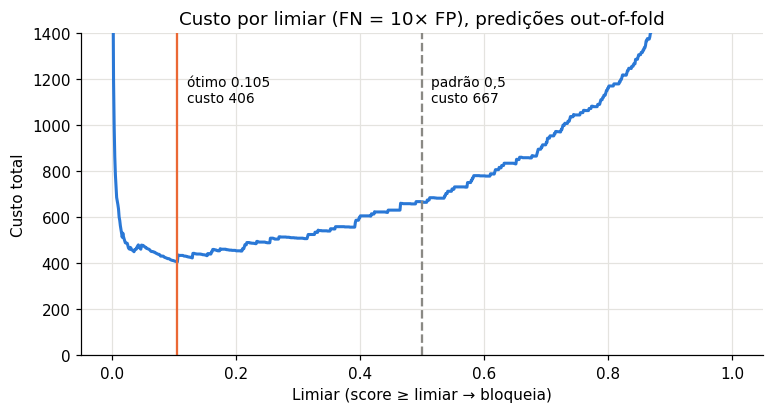

In [6]:
curva = evaluate.cost_curve(y_tr, scores_oof)
limiar = evaluate.best_threshold(y_tr, scores_oof)

padrao = evaluate.confusion_at(y_tr, scores_oof, 0.5)
otimo = evaluate.confusion_at(y_tr, scores_oof, limiar)
display(pd.DataFrame([padrao, otimo], index=["limiar 0,5", "limiar ótimo"]))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curva["limiar"], curva["custo"], color=AZUL, lw=2)
ax.axvline(0.5, color=CINZA, ls="--", lw=1.5)
ax.axvline(limiar, color=LARANJA, lw=1.5)
ax.annotate(f"padrão 0,5\ncusto {padrao['custo']:.0f}", (0.5, 1100),
            xytext=(6, 0), textcoords="offset points", fontsize=9)
ax.annotate(f"ótimo {limiar:.3f}\ncusto {otimo['custo']:.0f}",
            (limiar, 1100), xytext=(6, 0), textcoords="offset points", fontsize=9)
ax.set(xlabel="Limiar (score ≥ limiar → bloqueia)", ylabel="Custo total",
       ylim=(0, 1400), title="Custo por limiar (FN = 10× FP), predições out-of-fold")
plt.show()

O limiar ótimo cai para perto de 0,1: o modelo aceita bloquear mais sites
legítimos para deixar passar bem menos phishing. Com FN valendo 10, essa troca
reduz o custo total em cerca de 40%.

Como o limiar sai de `config.CostMatrix`, mudar a premissa de negócio
(ex.: FN = 5× FP) reajusta tudo sem tocar em código de modelagem.

## 4. Avaliação final no teste

Agora, e só agora, o teste é aberto. O modelo é treinado no treino inteiro e
aplicado ao teste com o limiar **já escolhido** na seção 3 — nada é
reescolhido aqui. Se algo daqui levasse a mudar o modelo e avaliar de novo, o
teste deixaria de ser uma estimativa sem viés.

A linha `oraculo_teste` é só diagnóstico: o melhor limiar *se* pudéssemos
olhar o teste. A distância entre ela e a escolhida mede se o limiar
generaliza.

In [7]:
modelo_final, teste = train.final_evaluation(X_tr, y_tr, X_te, y_te, limiar)
pd.DataFrame(teste).T.round(4)

,roc_auc,average_precision,recall,precision,limiar,fp,fn,custo
escolhido,0.9996,0.9996,1.0000,0.9572,0.105,41.0,0.0,41.0
padrao_0.5,0.9996,0.9996,0.9913,0.9848,0.500,14.0,8.0,94.0
oraculo_teste,0.9996,0.9996,1.0000,0.9612,0.125,37.0,0.0,37.0


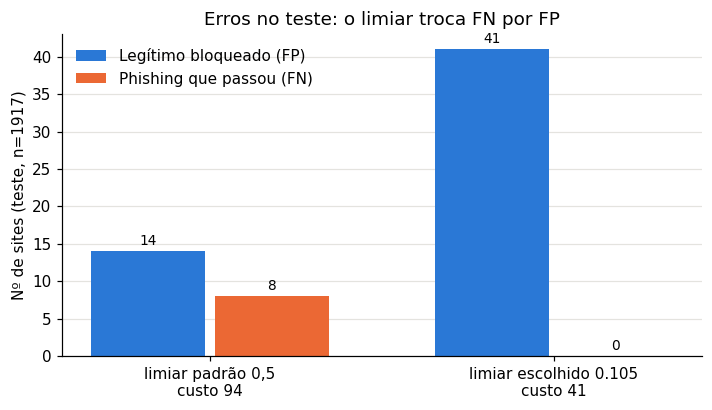

In [8]:
cenarios = {"limiar padrão 0,5": teste["padrao_0.5"],
            f"limiar escolhido {limiar:.3f}": teste["escolhido"]}
erros = [("fp", "Legítimo bloqueado (FP)", AZUL),
         ("fn", "Phishing que passou (FN)", LARANJA)]

x = np.arange(len(cenarios))
largura = 0.36
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (chave, rotulo, cor) in enumerate(erros):
    barras = ax.bar(x + (i - 0.5) * largura, [c[chave] for c in cenarios.values()],
                    width=largura - 0.03, color=cor, label=rotulo)
    ax.bar_label(barras, fontsize=9, padding=2)
ax.set_xticks(x, [f"{nome}\ncusto {c['custo']:.0f}" for nome, c in cenarios.items()])
ax.set(ylabel=f"Nº de sites (teste, n={len(y_te)})",
       title="Erros no teste: o limiar troca FN por FP")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.show()

**Leitura:**

- **Nenhum phishing passou** no limiar escolhido (contra 8 no 0,5). O preço
  foram 27 bloqueios indevidos a mais (41 vs 14), e o custo total caiu de 94
  para 41 (**−56%**).
- **O limiar generaliza:** o oráculo, que olha o teste, chegaria a custo 37 com
  limiar 0,125. O escolhido sem olhar ficou a 4 pontos disso.
- **Ressalva honesta:** a ROC-AUC no teste (0,9996) saiu *acima* da CV
  (0,9981 ± 0,0006). O teste é uma única amostra de 1.917 sites, então parte
  disso é sorte da partição. O número conservador para reportar é o da CV, e
  "zero phishings perdidos" vale para esta amostra, não é garantia.

## 5. Conclusões e limitações

**Conclusões**

1. O sinal é forte: até uma regressão logística chega a 0,98 de ROC-AUC. O
   gradient boosting leva a 0,998, empatado com random forest, e foi escolhido
   por ser mais leve.
2. HTML é a fonte mais informativa, mas URL e HTML são complementares — o
   conjunto completo erra menos que qualquer um sozinho.
3. A maior alavanca de negócio não foi o modelo, foi o **limiar**: escolhê-lo
   pelo custo cortou o custo em ~40% na validação e 56% no teste, sem mudar uma
   linha do modelo.

**Limitações**

- **Dataset de 2018, coletado num recorte específico.** Phishing muda rápido;
  em produção o modelo precisaria de monitoramento de drift e retreino.
- **Balanceamento artificial (≈50/50).** No tráfego real phishing é raro, e
  isso muda a precisão observada: com a mesma taxa de FP, a maioria dos
  bloqueios seria de sites legítimos. O limiar teria de ser recalibrado com a
  taxa real.
- **O detector recebe features prontas, não a URL crua.** Um sistema completo
  precisa de um extrator que calcule as 47 features a partir da URL e do HTML.
- **A matriz de custo (FN = 10× FP) é uma premissa**, não um fato medido. Ela
  está isolada em `config.CostMatrix` justamente para ser discutida e
  ajustada.